In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error

img = Image.open('lena.jpg')
img_gray = img.convert('L')
img_array = np.array(img_gray)

U, s, Vt = np.linalg.svd(img_array, full_matrices=False)
original_shape = img_array.shape
original_flat = img_array.flatten()
h, w = original_shape
weight = h*w
print(h,w,weight)

2048 2048 4194304


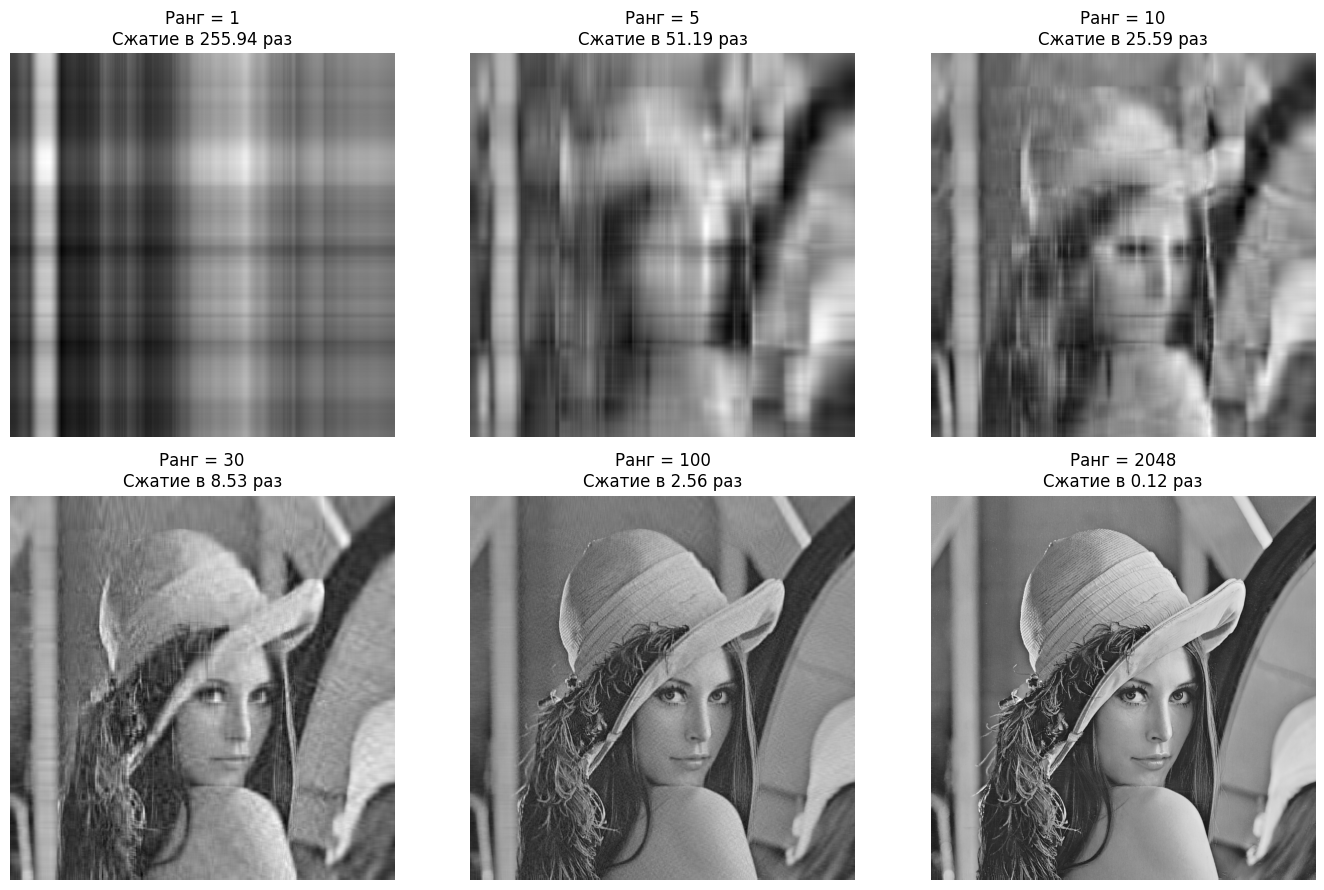

In [ ]:
list_of_ranks = [1, 5, 10, 30, 100, min(h, w)]
approximations = []
ratios = []

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for i, r in enumerate(list_of_ranks):
    U_r = U[:, :r]
    s_r = s[:r]
    Vt_r = Vt[:r, :]
    reconstructed = (U_r * s_r) @ Vt_r
    approximations.append(reconstructed)
    new_shape = reconstructed.shape
    n_h, n_w = new_shape
    n_weight = 4 * r * (n_h + 1 + n_w)
    ratio = weight / n_weight
    ratios.append(ratio)

    ax = axes[i]
    ax.imshow(reconstructed, cmap='gray')
    ax.set_title(f"Ранг = {r}\nСжатие в {ratio:.2f} раз")
    ax.axis('off')

plt.tight_layout()
plt.show()

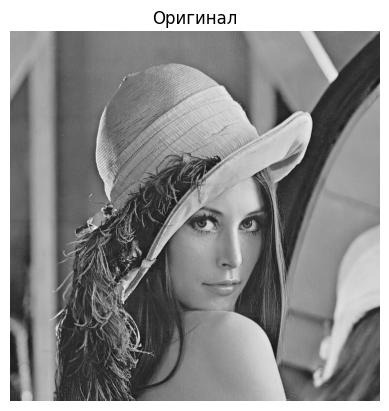

In [ ]:
plt.imshow(img_array, cmap='gray')
plt.title(f"Оригинал")
plt.axis('off')
plt.show()

In [ ]:
# 1. Проверка размерностей
for i, r in enumerate(list_of_ranks):
    assert approximations[i].shape == original_shape, f"Ошибка: размерность для ранга {r} не совпадает с исходной"

# 2. Проверка, что значения не выходят за пределы 0-255 (для RGB/серого)
for i, r in enumerate(list_of_ranks):
    arr = approximations[i]
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255) # Если float, то проверяем диапазон
    assert arr.max() <= 255.1, f"Значения превышают 255 для ранга {r}"
    assert arr.min() >= -0.1, f"Значения меньше 0 для ранга {r}"

# 3. Проверка, что с ростом ранга ошибка уменьшается (метрика MSE)
from sklearn.metrics import mean_squared_error
mse_list = []
for i in range(len(approximations)):
    # Если цветная, считаем MSE по всем каналам
    mse = mean_squared_error(original_flat, approximations[i].flatten())
    mse_list.append(mse)

# Проверяем монотонность (MSE должен падать, так как мы добавляем сингулярные числа)
for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6, f"MSE не уменьшается между рангами {list_of_ranks[i-1]} и {list_of_ranks[i]}"

print("✅ Все автоматические проверки пройдены. Задание выполнено корректно!")

✅ Все автоматические проверки пройдены. Задание выполнено корректно!
